# ECG Heartbeat Classifier (MIT-BIH Arrhythmia Database)


## 1. Setup

In [1]:
%pip install -q wfdb numpy pandas scipy scikit-learn matplotlib

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt, welch
from scipy.stats import skew, kurtosis

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
print("Libraries imported.")

Libraries imported.


In [3]:

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/mitdb"
except ImportError:
    DATA_DIR = "data/mit-bih-arrhythmia-database-1.0.0"

RANDOM_STATE = 42
PRE, POST = 90, 110
LOW_HZ, HIGH_HZ, FILTER_ORDER = 0.5, 40.0, 3
PACED_RECORDS = {"102", "104", "107", "217"}
DS1 = ["101","106","108","109","112","114","115","116","118","119","122","124","201","203","205",
       "207","208","209","215","220","223","230"]
DS2 = ["100","103","105","111","113","117","121","123","200","202","210","212","213","214","219",
       "221","222","228","231","232","233","234"]

CV_MAX_BEATS = 20000

Mounted at /content/drive


## 2. Load the data and check the leads


In [4]:
records = sorted({os.path.splitext(f)[0] for f in os.listdir(DATA_DIR) if f.endswith(".hea")})
print("Recordings found:", len(records))

print("Records where channel 0 is not MLII:")
for rid in records:
    hdr = wfdb.rdheader(os.path.join(DATA_DIR, rid))
    if hdr.sig_name[0] != "MLII":
        print("  ", rid, hdr.sig_name)

Recordings found: 48
Records where channel 0 is not MLII:
   102 ['V5', 'V2']
   104 ['V5', 'V2']
   114 ['V5', 'MLII']


In [5]:
def load_mlii(rid):
    """Return the MLII signal (mV) and the sampling rate, or (None, fs) if the record has no MLII."""
    rec = wfdb.rdrecord(os.path.join(DATA_DIR, rid))
    if "MLII" not in rec.sig_name:
        return None, rec.fs
    return rec.p_signal[:, rec.sig_name.index("MLII")], rec.fs

sig, fs = load_mlii("100")
ann = wfdb.rdann(os.path.join(DATA_DIR, "100"), "atr")
print("Sampling rate:", fs, "Hz | length:", len(sig), "samples |", round(len(sig) / fs / 60, 1), "minutes")
print("First annotations:", list(zip(ann.sample[:5], ann.symbol[:5])))

Sampling rate: 360 Hz | length: 650000 samples | 30.1 minutes
First annotations: [(np.int64(18), '+'), (np.int64(77), 'N'), (np.int64(370), 'N'), (np.int64(662), 'N'), (np.int64(946), 'N')]


## 3. Filtering


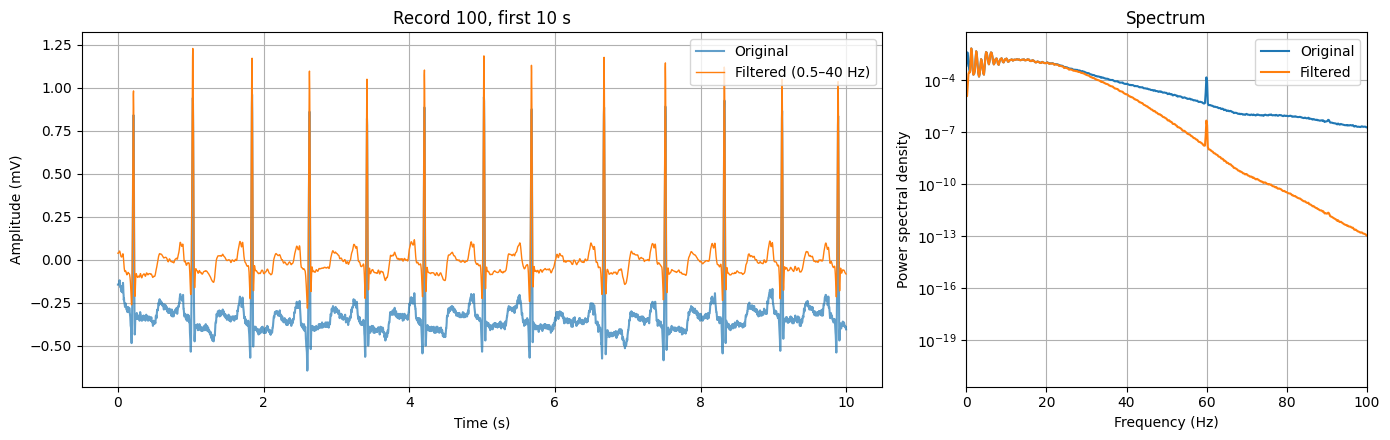

In [9]:
def filter_ecg(signal, fs, low=LOW_HZ, high=HIGH_HZ, order=FILTER_ORDER):
    b, a = butter(order, [low, high], btype="bandpass", fs=fs)
    return filtfilt(b, a, signal)

clean = filter_ecg(sig, fs)

n = 10 * fs
t = np.arange(n) / fs
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(t, sig[:n], alpha=0.7, label="Original")
ax[0].plot(t, clean[:n], lw=1, label="Filtered (0.5–40 Hz)")
ax[0].set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="Record 100, first 10 s")
ax[0].legend(); ax[0].grid(True)

f1_, p1 = welch(sig, fs=fs, nperseg=2048)
f2_, p2 = welch(clean, fs=fs, nperseg=2048)
ax[1].semilogy(f1_, p1, label="Original"); ax[1].semilogy(f2_, p2, label="Filtered")
ax[1].set(xlim=(0, 100), xlabel="Frequency (Hz)", ylabel="Power spectral density", title="Spectrum")
ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

## 4. Labels, beat windows and features



In [6]:
AAMI = {"N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
        "A": "S", "a": "S", "J": "S", "S": "S",
        "V": "V", "E": "V", "F": "F",
        "/": "Q", "f": "Q", "Q": "Q"}

FEATURE_NAMES = [f"morph_{i}" for i in range(PRE + POST)] + \
                ["RR_previous", "RR_next", "amplitude_p2p", "skewness", "kurtosis"]

def zscore(x):
    s = x.std()
    return np.zeros_like(x) if s < 1e-8 else (x - x.mean()) / s

def extract_beats(filtered, fs, samples, symbols):
    """Return (features, binary labels, AAMI classes) for one record."""
    keep = [(int(s), AAMI[c]) for s, c in zip(samples, symbols) if c in AAMI]
    if len(keep) < 3:
        return np.empty((0, len(FEATURE_NAMES))), [], []
    pos = np.array([p for p, _ in keep])
    rr_median = np.median(np.diff(pos)) / fs
    rows, labels, classes = [], [], []
    for i, (r, cls) in enumerate(keep):
        if cls == "Q" or r - PRE < 0 or r + POST > len(filtered):
            continue
        raw = filtered[r - PRE : r + POST]
        beat = zscore(raw)
        rr_prev = (r - pos[i - 1]) / fs if i > 0 else rr_median
        rr_next = (pos[i + 1] - r) / fs if i < len(pos) - 1 else rr_median
        feats = np.concatenate([beat, [rr_prev, rr_next, raw.max() - raw.min(), skew(beat), kurtosis(beat)]])
        if np.all(np.isfinite(feats)):
            rows.append(feats)
            labels.append(0 if cls == "N" else 1)
            classes.append(cls)
    return np.array(rows).reshape(-1, len(FEATURE_NAMES)), labels, classes

In [10]:
blocks, y_all, aami_all, group_all = [], [], [], []
t0 = time.time()
for rid in records:
    if rid in PACED_RECORDS:
        continue
    sig, fs = load_mlii(rid)
    if sig is None or not np.all(np.isfinite(sig)):
        print("Skipped record", rid)
        continue
    ann = wfdb.rdann(os.path.join(DATA_DIR, rid), "atr")
    feats, labels, classes = extract_beats(filter_ecg(sig, fs), fs, ann.sample, ann.symbol)
    blocks.append(feats); y_all += labels; aami_all += classes; group_all += [rid] * len(labels)

X = pd.DataFrame(np.vstack(blocks), columns=FEATURE_NAMES)
y = np.array(y_all); aami = np.array(aami_all); groups = np.array(group_all)
print(f"Done in {time.time() - t0:.0f} s")

Done in 272 s


In [11]:
print("Dataset shape:", X.shape)
print("Records used:", len(np.unique(groups)))
print(f"Normal: {(y == 0).sum()}   Abnormal: {(y == 1).sum()}   ({(y == 1).mean():.1%} abnormal)")
print(pd.Series(aami).value_counts().rename("beats").to_frame().T.to_string())

Dataset shape: (100690, 205)
Records used: 44
Normal: 90099   Abnormal: 10591   (10.5% abnormal)
           N     V     S    F
beats  90099  7008  2781  802


## 5. Patient-wise split



In [12]:
train_mask = np.isin(groups, DS1)
test_mask = np.isin(groups, DS2)

X_train, y_train, g_train, aami_train = X[train_mask].reset_index(drop=True), y[train_mask], groups[train_mask], aami[train_mask]
X_test,  y_test,  g_test,  aami_test  = X[test_mask].reset_index(drop=True),  y[test_mask],  groups[test_mask],  aami[test_mask]

assert not (set(g_train) & set(g_test)), "a record is in both sets"
print(f"Train (DS1): {len(y_train)} beats from {len(set(g_train))} records, {y_train.mean():.1%} abnormal")
print(f"Test  (DS2): {len(y_test)} beats from {len(set(g_test))} records, {y_test.mean():.1%} abnormal")

Train (DS1): 51000 beats from 22 records, 10.1% abnormal
Test  (DS2): 49690 beats from 22 records, 11.0% abnormal


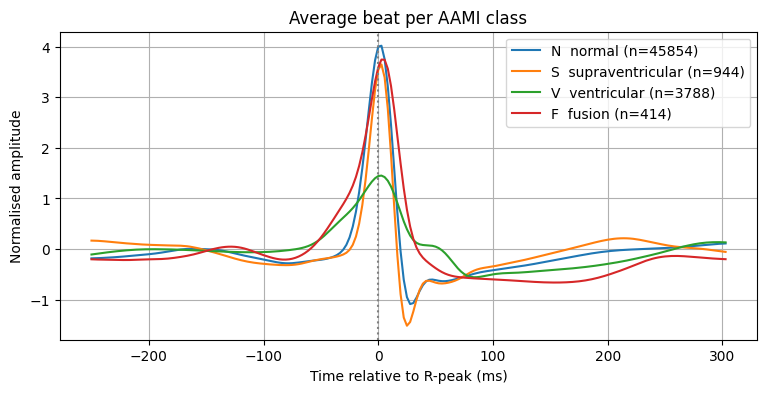

In [13]:

ms = (np.arange(PRE + POST) - PRE) / 360 * 1000
names = {"N": "N  normal", "S": "S  supraventricular", "V": "V  ventricular", "F": "F  fusion"}
plt.figure(figsize=(9, 4))
for cls, label in names.items():
    sel = aami_train == cls
    if sel.any():
        plt.plot(ms, X_train.loc[sel, FEATURE_NAMES[:PRE + POST]].mean().values, label=f"{label} (n={sel.sum()})")
plt.axvline(0, color="grey", ls=":")
plt.xlabel("Time relative to R-peak (ms)"); plt.ylabel("Normalised amplitude")
plt.title("Average beat per AAMI class"); plt.legend(); plt.grid(True); plt.show()

## 6. Model selection (cross-validation on DS1 )


In [14]:
def make_models():
    return {
        "Logistic Regression": make_pipeline(StandardScaler(),
            LogisticRegression(class_weight="balanced", max_iter=1000)),
        "KNN (k=5)": make_pipeline(StandardScaler(),
            KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
        "SVM (RBF)": make_pipeline(StandardScaler(),
            SVC(kernel="rbf", class_weight="balanced")),
        "Random Forest": make_pipeline(StandardScaler(),
            RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                   random_state=RANDOM_STATE, n_jobs=-1)),
    }

rng = np.random.default_rng(RANDOM_STATE)
if CV_MAX_BEATS and len(X_train) > CV_MAX_BEATS:
    idx = np.sort(rng.choice(len(X_train), CV_MAX_BEATS, replace=False))
else:
    idx = np.arange(len(X_train))
X_cv, y_cv, g_cv = X_train.iloc[idx], y_train[idx], g_train[idx]

scoring = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
rows = []
for name, model in make_models().items():
    t0 = time.time()
    res = cross_validate(model, X_cv, y_cv, groups=g_cv, cv=GroupKFold(n_splits=5), scoring=scoring)
    rows.append({"Model": name,
                 "Precision": res["test_precision"].mean(), "Recall": res["test_recall"].mean(),
                 "F1": res["test_f1"].mean(), "F1 std": res["test_f1"].std(),
                 "ROC-AUC": res["test_roc_auc"].mean(), "Seconds": time.time() - t0})
    print(f"{name:20s} F1 = {rows[-1]['F1']:.3f} ± {rows[-1]['F1 std']:.3f}   ({rows[-1]['Seconds']:.0f} s)")

cv_table = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
best_name = cv_table.loc[0, "Model"]
print("\nSelected by cross-validation:", best_name)
print(cv_table.round(3).to_string(index=False))

Logistic Regression  F1 = 0.532 ± 0.230   (33 s)
KNN (k=5)            F1 = 0.433 ± 0.128   (28 s)
SVM (RBF)            F1 = 0.474 ± 0.210   (51 s)
Random Forest        F1 = 0.606 ± 0.215   (299 s)

Selected by cross-validation: Random Forest
              Model  Precision  Recall    F1  F1 std  ROC-AUC  Seconds
      Random Forest      0.631   0.638 0.606   0.215    0.886  299.112
Logistic Regression      0.433   0.813 0.532   0.230    0.875   33.428
          SVM (RBF)      0.366   0.838 0.474   0.210    0.877   50.539
          KNN (k=5)      0.322   0.706 0.433   0.128    0.796   28.404


## 7. Final evaluation on DS2


In [15]:
def get_scores(model, X):
    """Probability of 'abnormal' if the model has one, otherwise the decision-function score."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

fitted, rows = {}, []
for name, model in make_models().items():
    t0 = time.time()
    model.fit(X_train, y_train)
    pred = model.predict(X_test); score = get_scores(model, X_test)
    fitted[name] = model
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred, zero_division=0),
                 "F1": f1_score(y_test, pred, zero_division=0),
                 "ROC-AUC": roc_auc_score(y_test, score)})
    print(f"fitted {name} in {time.time() - t0:.0f} s")

test_table = pd.DataFrame(rows).set_index("Model")
test_table.insert(0, "Chosen", ["yes" if m == best_name else "" for m in test_table.index])
print("\nDS2 results")
print(test_table.round(3).to_string())

fitted Logistic Regression in 20 s
fitted KNN (k=5) in 109 s
fitted SVM (RBF) in 194 s
fitted Random Forest in 266 s

DS2 results
                    Chosen  Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                                  
Logistic Regression            0.825      0.379   0.929  0.538    0.939
KNN (k=5)                      0.864      0.429   0.741  0.544    0.853
SVM (RBF)                      0.788      0.332   0.926  0.489    0.934
Random Forest          yes     0.938      0.840   0.540  0.657    0.878


Chosen model: Random Forest
              precision    recall  f1-score   support

      Normal      0.946     0.987     0.966     44245
    Abnormal      0.840     0.540     0.657      5445

    accuracy                          0.938     49690
   macro avg      0.893     0.764     0.812     49690
weighted avg      0.934     0.938     0.932     49690



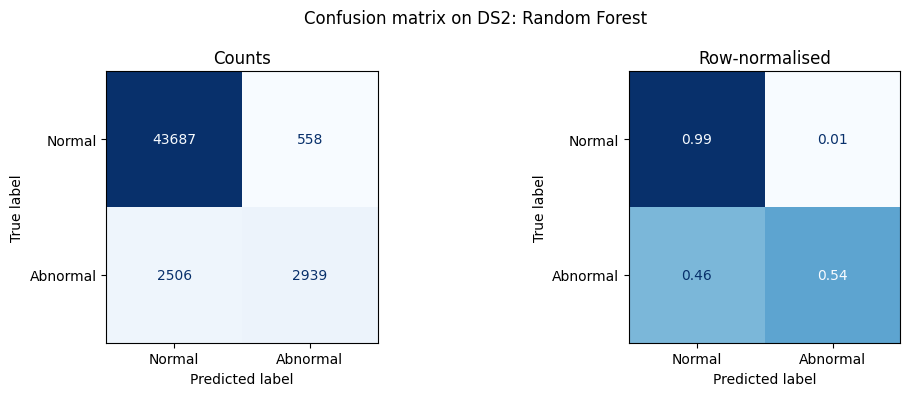

In [16]:
best = fitted[best_name]
pred = best.predict(X_test)
print("Chosen model:", best_name)
print(classification_report(y_test, pred, target_names=["Normal", "Abnormal"], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Normal", "Abnormal"]).plot(ax=ax[0], cmap="Blues", values_format="d", colorbar=False)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, normalize="true"), display_labels=["Normal", "Abnormal"]).plot(ax=ax[1], cmap="Blues", values_format=".2f", colorbar=False)
ax[0].set_title("Counts"); ax[1].set_title("Row-normalised")
plt.suptitle(f"Confusion matrix on DS2: {best_name}"); plt.tight_layout(); plt.show()

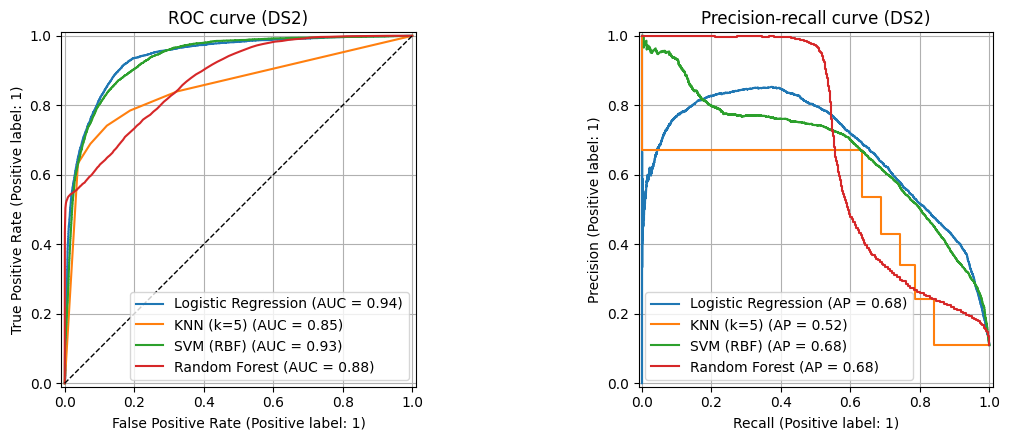

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, model in fitted.items():
    s = get_scores(model, X_test)
    RocCurveDisplay.from_predictions(y_test, s, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, s, name=name, ax=ax[1])
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC curve (DS2)")
ax[1].set_title("Precision-recall curve (DS2)")
for a in ax: a.grid(True)
plt.tight_layout(); plt.show()

In [18]:

desc = {"N": "Normal", "S": "Supraventricular ectopic", "V": "Ventricular ectopic", "F": "Fusion"}
rows = []
for cls, label in desc.items():
    sel = aami_test == cls
    if sel.any():
        correct = (pred[sel] == (0 if cls == "N" else 1)).mean()
        rows.append({"AAMI class": cls, "Type": label, "Beats": int(sel.sum()), "Classified correctly": f"{correct:.1%}"})
print(pd.DataFrame(rows).to_string(index=False))

df = pd.DataFrame({"record": g_test, "true": y_test, "pred": pred})
df["missed"] = (df.true == 1) & (df.pred == 0)
df["false_alarm"] = (df.true == 0) & (df.pred == 1)
per_record = df.groupby("record").agg(beats=("true", "size"), abnormal=("true", "sum"),
                                      missed=("missed", "sum"), false_alarms=("false_alarm", "sum"))
per_record["abnormal_recall"] = 1 - per_record["missed"] / per_record["abnormal"].replace(0, np.nan)
print("\nPer test record:")
print(per_record.round(3).to_string())

AAMI class                     Type  Beats Classified correctly
         N                   Normal  44245                98.7%
         S Supraventricular ectopic   1837                 3.2%
         V      Ventricular ectopic   3220                88.1%
         F                   Fusion    388                11.1%

Per test record:
        beats  abnormal  missed  false_alarms  abnormal_recall
record                                                        
100      2271        34      27             0            0.206
103      2084         2       2             0            0.000
105      2567        41      33            53            0.195
111      2124         1       0           100            1.000
113      1794         6       6             0            0.000
117      1534         1       1           196            0.000
121      1863         2       1             2            0.500
123      1517         3       0             1            1.000
200      2600       858      77 

## 8. PCA visualisation



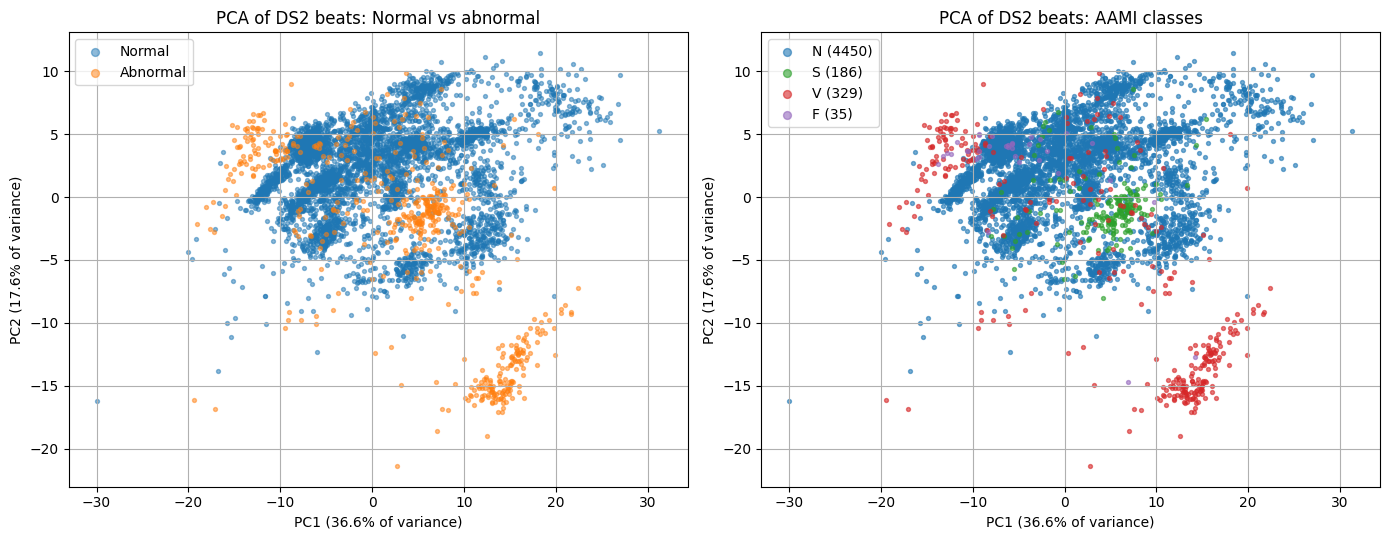

In [19]:
rng = np.random.default_rng(RANDOM_STATE)
tr_idx = rng.choice(len(X_train), min(10000, len(X_train)), replace=False)
te_idx = rng.choice(len(X_test), min(5000, len(X_test)), replace=False)

scaler = StandardScaler().fit(X_train.iloc[tr_idx])
pca = PCA(random_state=RANDOM_STATE).fit(scaler.transform(X_train.iloc[tr_idx]))
Z = pca.transform(scaler.transform(X_test.iloc[te_idx]))
yy, cc = y_test[te_idx], aami_test[te_idx]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for lab, name, col in [(0, "Normal", "tab:blue"), (1, "Abnormal", "tab:orange")]:
    m = yy == lab
    ax[0].scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, label=name, c=col)
for cls, col in [("N", "tab:blue"), ("S", "tab:green"), ("V", "tab:red"), ("F", "tab:purple")]:
    m = cc == cls
    if m.any():
        ax[1].scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.6, label=f"{cls} ({m.sum()})", c=col)
for a, t in zip(ax, ["Normal vs abnormal", "AAMI classes"]):
    a.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)", title=f"PCA of DS2 beats: {t}")
    a.legend(markerscale=2); a.grid(True)
plt.tight_layout(); plt.show()

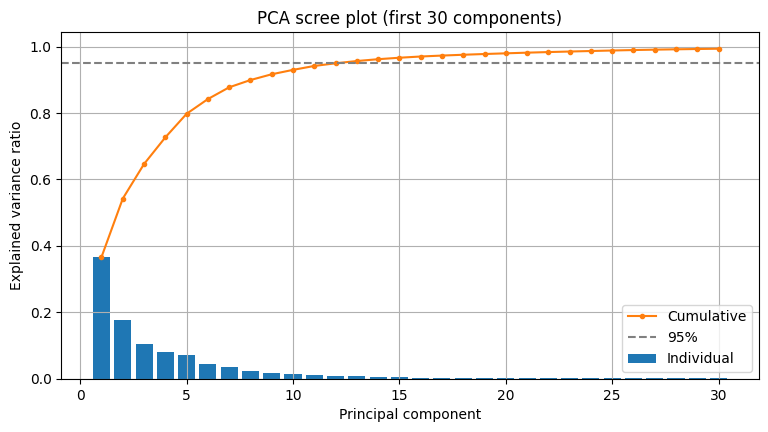

PC1 + PC2 explain 54.2% of the variance
Components needed for 95% of the variance: 13


In [20]:
ratio = pca.explained_variance_ratio_
cum = np.cumsum(ratio)
k = 30
plt.figure(figsize=(9, 4.5))
plt.bar(range(1, k + 1), ratio[:k], label="Individual")
plt.plot(range(1, k + 1), cum[:k], "o-", color="tab:orange", ms=3, label="Cumulative")
plt.axhline(0.95, ls="--", color="grey", label="95%")
plt.xlabel("Principal component"); plt.ylabel("Explained variance ratio")
plt.title("PCA scree plot (first 30 components)"); plt.legend(); plt.grid(True); plt.show()

print(f"PC1 + PC2 explain {cum[1]:.1%} of the variance")
print("Components needed for 95% of the variance:", int(np.searchsorted(cum, 0.95) + 1))

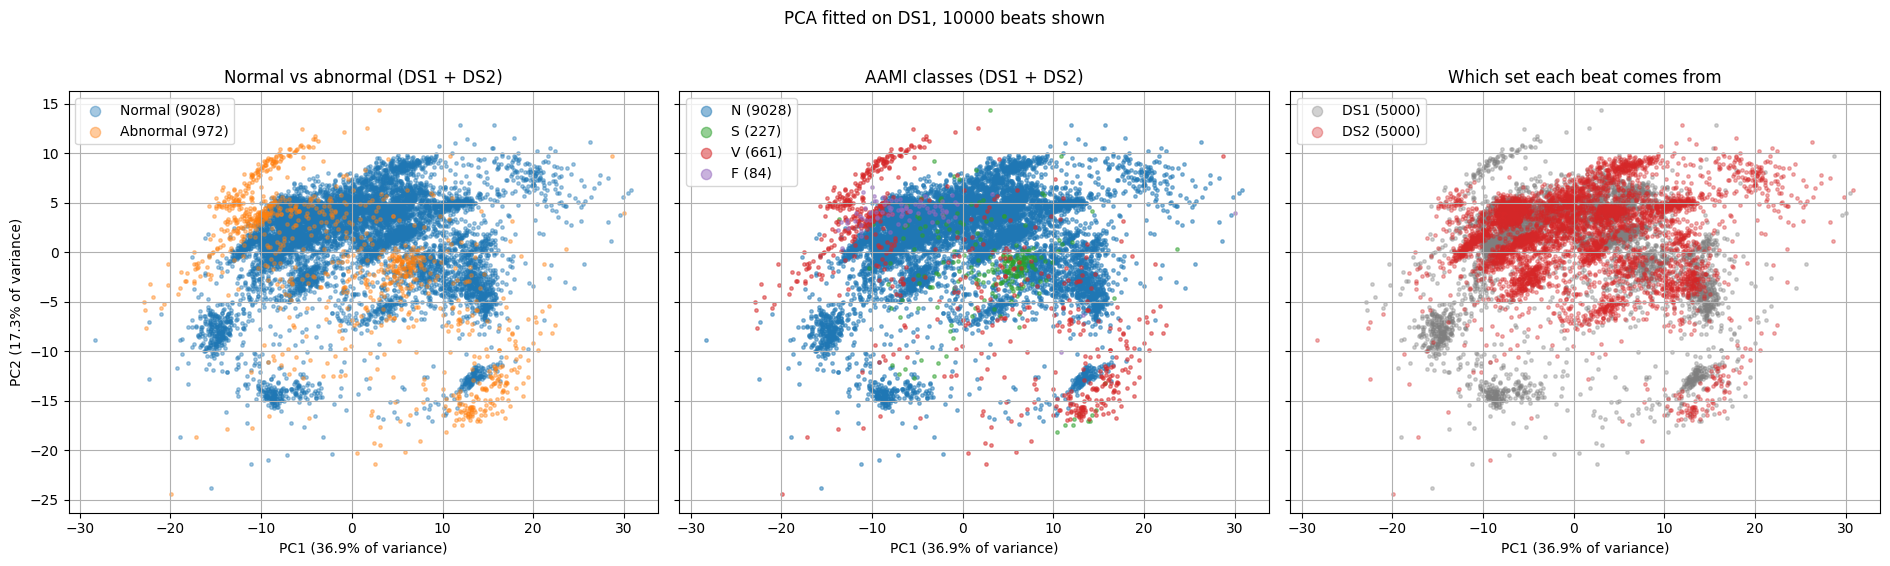

PC1 + PC2 explain 54.3% of the variance


In [21]:
FIT_PCA_ON = "DS1"
N_EACH = 5000

rng = np.random.default_rng(RANDOM_STATE)
i1 = rng.choice(len(X_train), min(N_EACH, len(X_train)), replace=False)
i2 = rng.choice(len(X_test),  min(N_EACH, len(X_test)),  replace=False)

X_viz = pd.concat([X_train.iloc[i1], X_test.iloc[i2]], ignore_index=True)
y_viz = np.concatenate([y_train[i1], y_test[i2]])
c_viz = np.concatenate([aami_train[i1], aami_test[i2]])
set_viz = np.array(["DS1"] * len(i1) + ["DS2"] * len(i2))

fit_rows = (set_viz == "DS1") if FIT_PCA_ON == "DS1" else np.ones(len(X_viz), dtype=bool)
scaler_v = StandardScaler().fit(X_viz[fit_rows])
pca_v = PCA(random_state=RANDOM_STATE).fit(scaler_v.transform(X_viz[fit_rows]))
Zv = pca_v.transform(scaler_v.transform(X_viz))

fig, ax = plt.subplots(1, 3, figsize=(19, 5.5), sharex=True, sharey=True)

for lab, name, col in [(0, "Normal", "tab:blue"), (1, "Abnormal", "tab:orange")]:
    m = y_viz == lab
    ax[0].scatter(Zv[m, 0], Zv[m, 1], s=6, alpha=0.4, c=col, label=f"{name} ({m.sum()})")
ax[0].set_title("Normal vs abnormal (DS1 + DS2)")

for cls, col in [("N", "tab:blue"), ("S", "tab:green"), ("V", "tab:red"), ("F", "tab:purple")]:
    m = c_viz == cls
    if m.any():
        ax[1].scatter(Zv[m, 0], Zv[m, 1], s=6, alpha=0.5, c=col, label=f"{cls} ({m.sum()})")
ax[1].set_title("AAMI classes (DS1 + DS2)")

for name, col in [("DS1", "tab:gray"), ("DS2", "tab:red")]:
    m = set_viz == name
    ax[2].scatter(Zv[m, 0], Zv[m, 1], s=6, alpha=0.35, c=col, label=f"{name} ({m.sum()})")
ax[2].set_title("Which set each beat comes from")

for a in ax:
    a.set_xlabel(f"PC1 ({pca_v.explained_variance_ratio_[0]:.1%} of variance)")
    a.legend(markerscale=3); a.grid(True)
ax[0].set_ylabel(f"PC2 ({pca_v.explained_variance_ratio_[1]:.1%} of variance)")
plt.suptitle(f"PCA fitted on {FIT_PCA_ON}, {len(X_viz)} beats shown", y=1.02)
plt.tight_layout(); plt.show()

print(f"PC1 + PC2 explain {pca_v.explained_variance_ratio_[:2].sum():.1%} of the variance")

## 9. Save the results

In [22]:
cv_table.to_csv("ecg_cv_results.csv", index=False)
test_table.to_csv("ecg_test_results.csv")
per_record.to_csv("ecg_per_record_results.csv")
print("Saved ecg_cv_results.csv, ecg_test_results.csv, ecg_per_record_results.csv")
try:
    from google.colab import files
    for f in ["ecg_cv_results.csv", "ecg_test_results.csv", "ecg_per_record_results.csv"]:
        files.download(f)
except ImportError:
    pass

Saved ecg_cv_results.csv, ecg_test_results.csv, ecg_per_record_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>